<a href="https://colab.research.google.com/github/deva123932/CSA-4703-DL/blob/main/exp_26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 26: Gibbs Sampling and Contrastive Divergence Analysis

In this experiment, we explore Restricted Boltzmann Machines (RBMs) to understand how the number of Gibbs steps affects training quality and computation.

We will:
1. Implement block Gibbs sampling.
2. Observe sampling chains starting from random noise.
3. Train RBMs using CD-1, CD-5, CD-10, and Persistent CD (PCD).
4. Compare reconstruction errors and pseudo-log-likelihood (PLL).
5. Analyze the trade-offs between computational overhead and sample quality.

## Setup and Dataset Preparation
We generate a binarized synthetic dataset resembling stylized hand-written digits or patterns (binarized MNIST-like patterns) for fast and clean training.

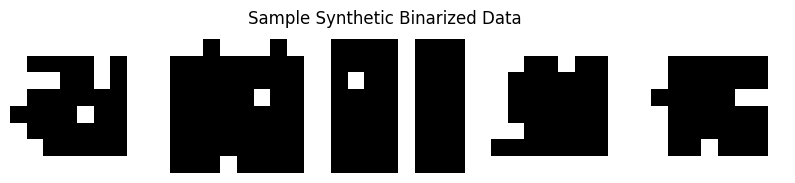

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time

# Set random seed for reproducibility
np.random.seed(42)

# Generate stylized 8x8 synthetic digits (horizontal & vertical bars)
def generate_synthetic_data(num_samples=1000):
    data = np.zeros((num_samples, 64))
    for i in range(num_samples):
        pattern_type = np.random.choice([0, 1, 2])
        img = np.zeros((8, 8))
        if pattern_type == 0:  # Horizontal bar
            img[np.random.randint(0, 8), :] = 1
        elif pattern_type == 1:  # Vertical bar
            img[:, np.random.randint(0, 8)] = 1
        else:  # Outer border
            img[0, :] = img[-1, :] = img[:, 0] = img[:, -1] = 1
        # Add small binary noise
        noise = np.random.rand(8, 8) < 0.05
        img = np.logical_xor(img, noise).astype(float)
        data[i] = img.flatten()
    return data

X_train = generate_synthetic_data(1000)

# Visualize some samples
fig, axes = plt.subplots(1, 5, figsize=(10, 2))
for i, ax in enumerate(axes):
    ax.imshow(X_train[i].reshape(8, 8), cmap='gray')
    ax.axis('off')
plt.suptitle("Sample Synthetic Binarized Data")
plt.show()

## Task 1: Block Gibbs Sampling Implementation
An RBM defines a bipartite graph between visible units $v$ and hidden units $h$. We implement functions to compute conditional probabilities $P(h|v)$ and $P(v|h)$, and perform block Gibbs sampling.

In [2]:
class RBM:
    def __init__(self, num_visible=64, num_hidden=16):
        self.W = np.random.normal(0, 0.1, (num_visible, num_hidden))
        self.v_bias = np.zeros(num_visible)
        self.h_bias = np.zeros(num_hidden)

    def sigmoid(self, x):
        return 1 / (1 + np.exp(-np.clip(x, -50, 50)))

    def sample_h_given_v(self, v):
        prob_h = self.sigmoid(np.dot(v, self.W) + self.h_bias)
        h_sample = (np.random.rand(*prob_h.shape) < prob_h).astype(float)
        return prob_h, h_sample

    def sample_v_given_h(self, h):
        prob_v = self.sigmoid(np.dot(h, self.W.T) + self.v_bias)
        v_sample = (np.random.rand(*prob_v.shape) < prob_v).astype(float)
        return prob_v, v_sample

    def gibbs_step(self, v):
        prob_h, h_sample = self.sample_h_given_v(v)
        prob_v, v_sample = self.sample_v_given_h(h_sample)
        return prob_h, h_sample, prob_v, v_sample

## Task 2: Analyze Gibbs Sampling Chains from Random Noise
We initialize Gibbs chains with uniform random noise and monitor the generated visible reconstructions after 1, 10, 100, and 1000 steps.

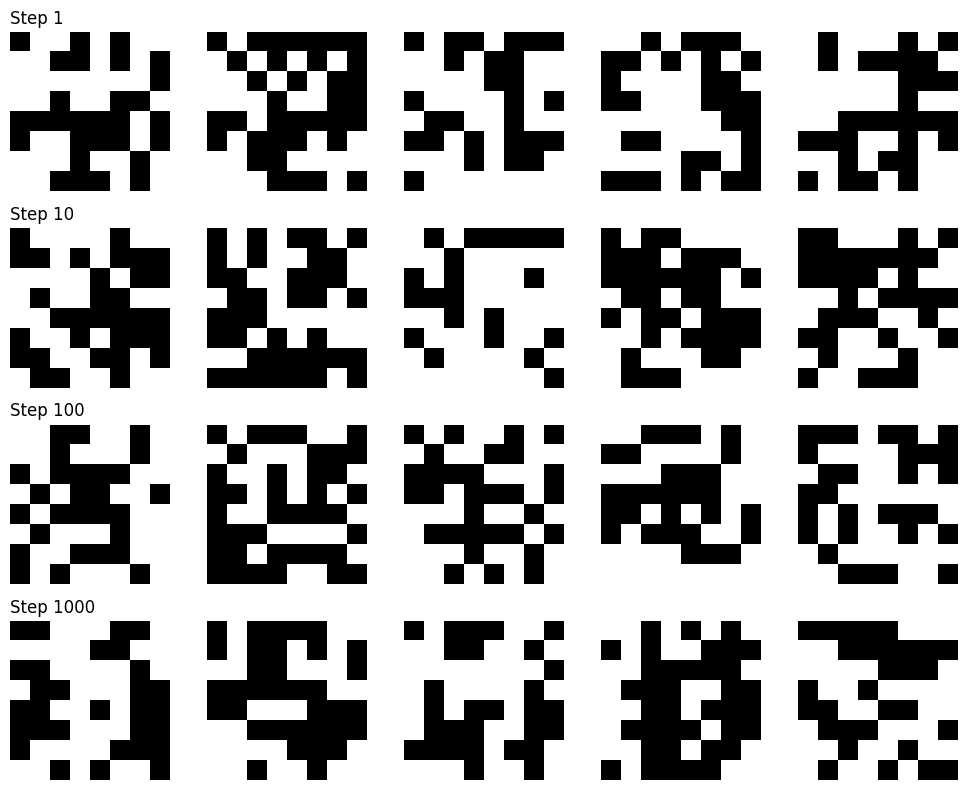

In [3]:
# Initialize a random RBM
rbm_toy = RBM(num_visible=64, num_hidden=16)

# Initialize sample chains with random binary noise
num_chains = 5
v_chain = (np.random.rand(num_chains, 64) > 0.5).astype(float)

steps_to_save = [1, 10, 100, 1000]
samples_saved = {}

current_v = v_chain.copy()
for step in range(1, 1001):
    _, _, _, current_v = rbm_toy.gibbs_step(current_v)
    if step in steps_to_save:
        samples_saved[step] = current_v.copy()

# Plot the evolution of chains
fig, axes = plt.subplots(len(steps_to_save), num_chains, figsize=(10, 8))
for r_idx, step in enumerate(steps_to_save):
    for c_idx in range(num_chains):
        ax = axes[r_idx, c_idx]
        ax.imshow(samples_saved[step][c_idx].reshape(8, 8), cmap='gray')
        ax.axis('off')
        if c_idx == 0:
            ax.set_title(f"Step {step}", loc='left', fontsize=12)

plt.tight_layout()
plt.show()

## Task 3: Train RBMs with CD-1, CD-5, CD-10, and PCD
We now implement Contrastive Divergence ($CD-k$) and Persistent Contrastive Divergence ($PCD$). Under PCD, the Gibbs sampling chain is not reinitialized at each gradient step; instead, we keep track of persistent particles.

In [4]:
def calculate_pll(rbm, X, num_runs=5):
    # Pseudo-log-likelihood approximation
    # Flip one random bit per visible sample and estimate likelihood ratio
    num_samples, num_visible = X.shape
    pll = 0.0
    for _ in range(num_runs):
        flipped_idx = np.random.randint(0, num_visible, size=num_samples)
        X_flipped = X.copy()
        X_flipped[np.arange(num_samples), flipped_idx] = 1 - X_flipped[np.arange(num_samples), flipped_idx]

        # Energy differences
        # E(v) = - v_bias * v - sum(softplus(v W + h_bias))
        def energy(v):
            linear_term = np.dot(v, rbm.v_bias)
            activation = np.dot(v, rbm.W) + rbm.h_bias
            hidden_term = np.sum(np.log(1 + np.exp(np.clip(activation, -50, 50))), axis=1)
            return -linear_term - hidden_term

        e_orig = energy(X)
        e_flipped = energy(X_flipped)

        # Sigmoid of energy difference yields conditional probability
        pll += np.mean(-np.log(1 + np.exp(e_orig - e_flipped)))
    return pll / num_runs

def train_rbm(method='CD-1', epochs=30, lr=0.1, batch_size=64):
    rbm = RBM(num_visible=64, num_hidden=16)
    num_samples = X_train.shape[0]

    # Metrics to track
    reconstruction_errors = []
    pll_scores = []

    start_time = time.time()

    # Persistent particles for PCD
    persistent_visible = (np.random.rand(batch_size, 64) > 0.5).astype(float)

    k = 1 if method == 'CD-1' else (5 if method == 'CD-5' else 10)

    for epoch in range(epochs):
        # Shuffle data
        shuffled_indices = np.random.permutation(num_samples)
        X_shuffled = X_train[shuffled_indices]

        epoch_error = 0
        for i in range(0, num_samples, batch_size):
            v_batch = X_shuffled[i:i+batch_size]
            actual_batch_size = v_batch.shape[0]
            if actual_batch_size < batch_size: continue

            # Positive Phase
            prob_h0, h0 = rbm.sample_h_given_v(v_batch)
            positive_grad = np.dot(v_batch.T, prob_h0)

            # Negative Phase
            if method == 'PCD':
                # Continue Gibbs chain from persistent particles
                v_k = persistent_visible.copy()
                for _ in range(1):
                    _, _, prob_v_k, v_k = rbm.gibbs_step(v_k)
                persistent_visible = v_k.copy()
            else: # Standard CD-k
                v_k = v_batch.copy()
                for _ in range(k):
                    _, _, prob_v_k, v_k = rbm.gibbs_step(v_k)

            prob_hk, _ = rbm.sample_h_given_v(v_k)
            negative_grad = np.dot(v_k.T, prob_hk)

            # Updates
            rbm.W += lr * (positive_grad - negative_grad) / actual_batch_size
            rbm.v_bias += lr * np.mean(v_batch - v_k, axis=0)
            rbm.h_bias += lr * np.mean(prob_h0 - prob_hk, axis=0)

            epoch_error += np.mean((v_batch - v_k) ** 2)

        reconstruction_errors.append(epoch_error / (num_samples // batch_size))
        pll_scores.append(calculate_pll(rbm, X_train))

    elapsed = time.time() - start_time
    return rbm, reconstruction_errors, pll_scores, elapsed

# Run training for all variations
methods = ['CD-1', 'CD-5', 'CD-10', 'PCD']
results = {}
for method in methods:
    print(f"Training RBM with {method}...")
    rbm, rec, pll, t = train_rbm(method=method, epochs=40)
    results[method] = {"rbm": rbm, "reconstruction_errors": rec, "pll": pll, "time": t}

Training RBM with CD-1...
Training RBM with CD-5...
Training RBM with CD-10...
Training RBM with PCD...


## Task 4: Plot Reconstruction Error and Pseudo-Log-Likelihood
We plot metrics tracked over epochs for a comprehensive visual comparative analysis.

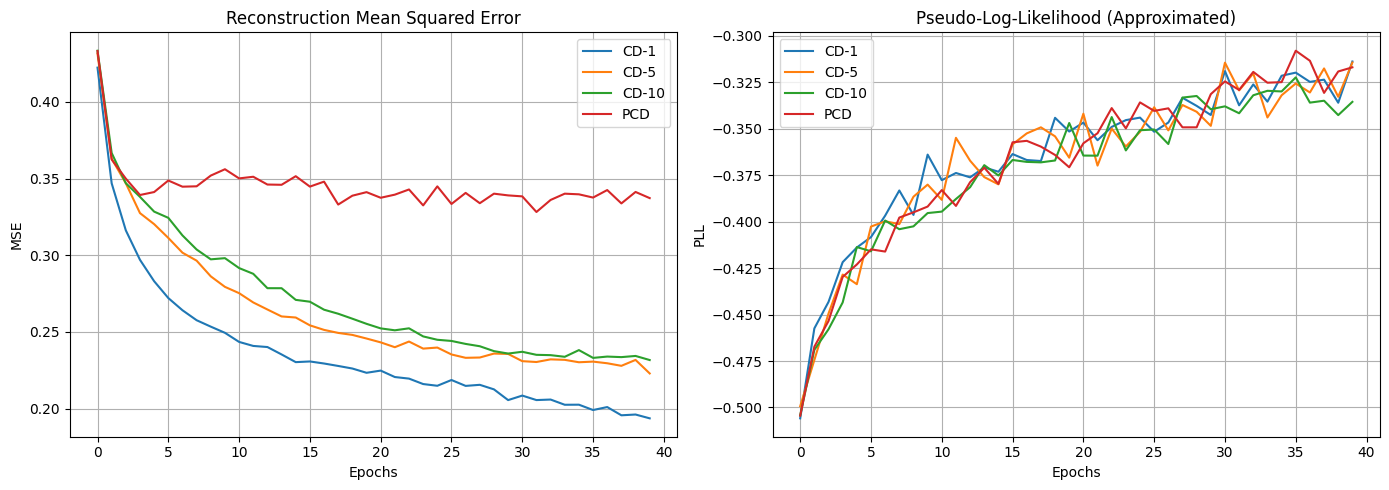

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for method in methods:
    ax1.plot(results[method]["reconstruction_errors"], label=method)
    ax2.plot(results[method]["pll"], label=method)

ax1.set_title("Reconstruction Mean Squared Error")
ax1.set_xlabel("Epochs")
ax1.set_ylabel("MSE")
ax1.grid(True)
ax1.legend()

ax2.set_title("Pseudo-Log-Likelihood (Approximated)")
ax2.set_xlabel("Epochs")
ax2.set_ylabel("PLL")
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()

## Task 5: Compare Training Time against Sample Quality
Finally, we evaluate the computational tradeoffs: more steps improve sample modeling accuracy (better pseudo-log-likelihood / final reconstruction), but come at a linear training duration penalty.

Method     | Training Time (s)  | Final Recon Error  | Final Pseudo-LL
----------------------------------------------------------------------
CD-1       | 0.440              | 0.1936             | -0.3138        
CD-5       | 0.859              | 0.2229             | -0.3143        
CD-10      | 1.354              | 0.2316             | -0.3355        
PCD        | 0.451              | 0.3372             | -0.3169        


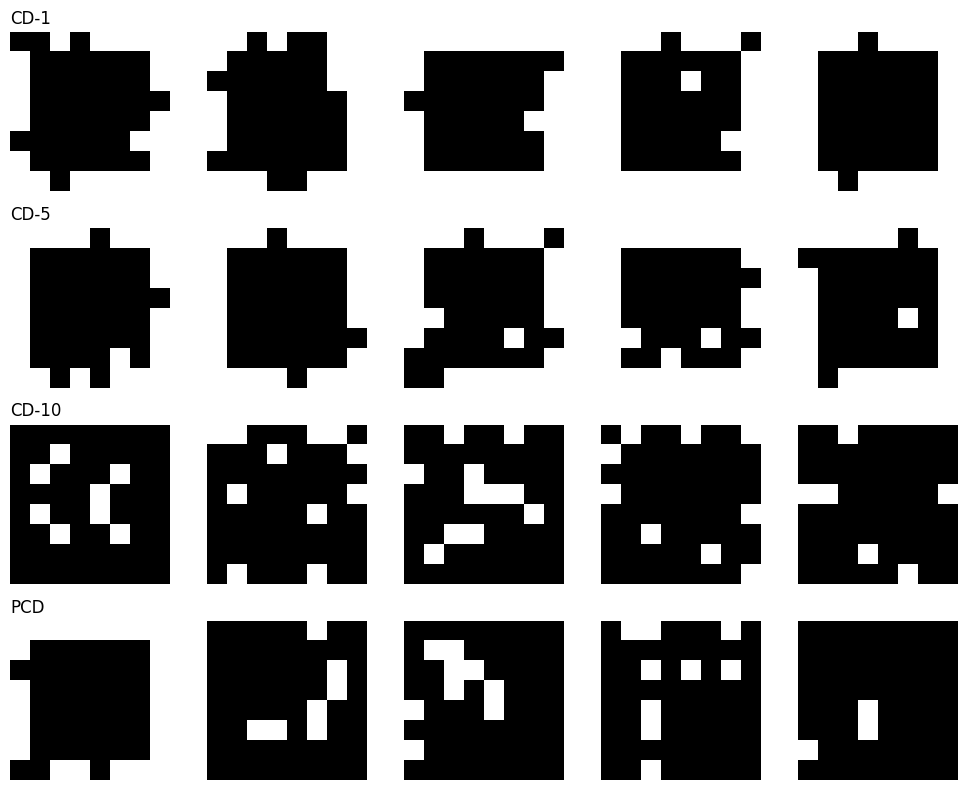

In [6]:
print(f"{'Method':<10} | {'Training Time (s)':<18} | {'Final Recon Error':<18} | {'Final Pseudo-LL':<15}")
print("-" * 70)
for method in methods:
    print(f"{method:<10} | {results[method]['time']:<18.3f} | {results[method]['reconstruction_errors'][-1]:<18.4f} | {results[method]['pll'][-1]:<15.4f}")

# Draw some final samples from each trained RBM starting from noise
fig, axes = plt.subplots(len(methods), 5, figsize=(10, 8))
for r_idx, method in enumerate(methods):
    rbm = results[method]["rbm"]
    v_sample = (np.random.rand(5, 64) > 0.5).astype(float)
    # Run 100 Gibbs steps to reach equilibrium
    for _ in range(100):
        _, _, _, v_sample = rbm.gibbs_step(v_sample)

    for c_idx in range(5):
        ax = axes[r_idx, c_idx]
        ax.imshow(v_sample[c_idx].reshape(8, 8), cmap='gray')
        ax.axis('off')
        if c_idx == 0:
            ax.set_title(method, loc='left', fontsize=12)

plt.tight_layout()
plt.show()